# Bài thực hành Buổi 1 - Bài 2 Trang 45
## Groceries Dataset

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1: Nhận diện dữ liệu, tạo one-hot và chạy Apriori theo 10 mức support

In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Tự động nhận diện groceries.csv hoặc Groceries_dataset.csv
from pathlib import Path

candidates = [p for p in [Path("groceries.csv"), Path("Groceries_dataset.csv")] if p.exists()]
if not candidates:
    raise FileNotFoundError("Không tìm thấy groceries.csv hoặc Groceries_dataset.csv")

groceries_file = candidates[0]

if groceries_file.name.lower() == "groceries.csv":
    # Mỗi dòng là một danh sách giao dịch
    transactions = []
    with open(groceries_file, "r", encoding="utf-8-sig") as f:
        for line in f:
            items = [item.strip() for item in line.strip().split(",") if item.strip()]
            if items:
                transactions.append(items)
else:
    # Dạng bảng Member_number, Date, itemDescription
    raw = pd.read_csv(groceries_file)
    if {"Member_number", "Date", "itemDescription"}.issubset(raw.columns):
        transactions = raw.groupby(["Member_number", "Date"])["itemDescription"].apply(
            lambda values: [str(value).strip() for value in values if str(value).strip()]
        ).tolist()
    else:
        raise ValueError("Không nhận diện được cấu trúc Groceries_dataset.csv")

encoder = TransactionEncoder()
encoded = encoder.fit(transactions).transform(transactions, sparse=True)
basket_groceries = pd.DataFrame.sparse.from_spmatrix(encoded, columns=encoder.columns_)
print("File:", groceries_file)
print("Số giao dịch:", len(transactions), "- Số sản phẩm:", basket_groceries.shape[1])
display(basket_groceries.head())

supports = np.linspace(0.001, 0.01, 10)
apriori_times = []
apriori_item_counts = []
for support in supports:
    start = time.time()
    items = apriori(basket_groceries, min_support=float(support), use_colnames=True, low_memory=True)
    elapsed = time.time() - start
    apriori_times.append(elapsed)
    apriori_item_counts.append(len(items))
    print(f"Apriori - support={support:.6f}: {elapsed:.4f}s, {len(items)} tập phổ biến")


Ngô Thành Khôi - 6451071038
File: groceries.csv
Số giao dịch: 9835 - Số sản phẩm: 169


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


Apriori - support=0.001000: 3.4146s, 13492 tập phổ biến
Apriori - support=0.002000: 1.0838s, 4223 tập phổ biến
Apriori - support=0.003000: 0.5923s, 2226 tập phổ biến
Apriori - support=0.004000: 0.4040s, 1398 tập phổ biến
Apriori - support=0.005000: 0.2929s, 1001 tập phổ biến
Apriori - support=0.006000: 0.2134s, 747 tập phổ biến
Apriori - support=0.007000: 0.1744s, 594 tập phổ biến
Apriori - support=0.008000: 0.1473s, 485 tập phổ biến
Apriori - support=0.009000: 0.1329s, 404 tập phổ biến
Apriori - support=0.010000: 0.1032s, 333 tập phổ biến


### Câu 2: Chạy FP-Growth trên chính 10 mức support

In [5]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Ghi nhận thời gian xử lý FP-Growth
fp_times = []
fp_item_counts = []
for support in supports:
    start = time.time()
    items = fpgrowth(basket_groceries, min_support=float(support), use_colnames=True)
    elapsed = time.time() - start
    fp_times.append(elapsed)
    fp_item_counts.append(len(items))
    print(f"FP-Growth - support={support:.6f}: {elapsed:.4f}s, {len(items)} tập phổ biến")


Ngô Thành Khôi - 6451071038
FP-Growth - support=0.001000: 0.8125s, 13492 tập phổ biến
FP-Growth - support=0.002000: 0.4624s, 4223 tập phổ biến
FP-Growth - support=0.003000: 0.3865s, 2226 tập phổ biến
FP-Growth - support=0.004000: 0.3561s, 1398 tập phổ biến
FP-Growth - support=0.005000: 0.1944s, 1001 tập phổ biến
FP-Growth - support=0.006000: 0.3060s, 747 tập phổ biến
FP-Growth - support=0.007000: 0.2736s, 594 tập phổ biến
FP-Growth - support=0.008000: 0.1687s, 485 tập phổ biến
FP-Growth - support=0.009000: 0.2655s, 404 tập phổ biến
FP-Growth - support=0.010000: 0.1400s, 333 tập phổ biến


### Câu 3: So sánh thời gian Apriori và FP-Growth

Ngô Thành Khôi - 6451071038


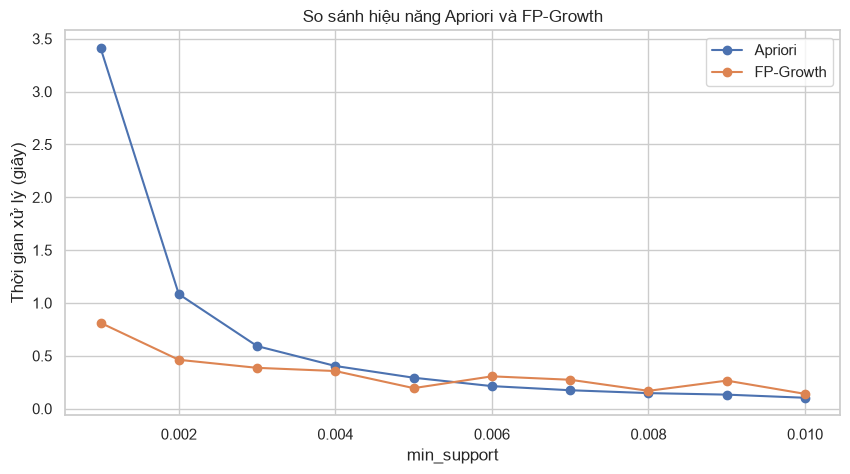

,min_support,Apriori_time_sec,Apriori_itemsets,FP_Growth_time_sec,FP_Growth_itemsets
0,0.001,3.414613,13492,0.812486,13492
1,0.002,1.083766,4223,0.462384,4223
2,0.003,0.592256,2226,0.386452,2226
3,0.004,0.403960,1398,0.356070,1398
4,0.005,0.292887,1001,0.194415,1001
5,0.006,0.213435,747,0.306024,747
6,0.007,0.174449,594,0.273558,594
7,0.008,0.147303,485,0.168697,485
8,0.009,0.132893,404,0.265545,404
9,0.010,0.103188,333,0.140049,333


In [6]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Vẽ đường thời gian theo min_support
plt.figure(figsize=(10, 5))
plt.plot(supports, apriori_times, marker="o", label="Apriori")
plt.plot(supports, fp_times, marker="o", label="FP-Growth")
plt.xlabel("min_support")
plt.ylabel("Thời gian xử lý (giây)")
plt.title("So sánh hiệu năng Apriori và FP-Growth")
plt.grid(True)
plt.legend()
plt.show()

comparison = pd.DataFrame({
    "min_support": supports,
    "Apriori_time_sec": apriori_times,
    "Apriori_itemsets": apriori_item_counts,
    "FP_Growth_time_sec": fp_times,
    "FP_Growth_itemsets": fp_item_counts,
})
display(comparison)


**Nhận xét:** Khi support giảm, số lượng tập phổ biến tăng nhanh nên thời gian hai thuật toán đều có xu hướng tăng. FP-Growth thường ổn định và nhanh hơn ở các dữ liệu dày do nén dữ liệu thành FP-tree và không phải tạo nhiều tập ứng viên lặp; Apriori quét cơ sở dữ liệu và sinh tập ứng viên nhiều lần nên chậm hơn ở support thấp.